- Objetivo: explorar e validar a base oficial de bairros de Salvador.
- Nome do arquivo e endereço da fonte de download.
- Data do download (12/10/2026)
- Resultado: 171 registros, CRS EPSG:31984 e geometrias MultiPolygon.
- Validações: nenhum nome ausente ou duplicado; nenhuma geometria ausente, vazia ou inválida.

In [1]:
import sys 
print(sys.executable)

/home/emanu/projetos/ftl-projeto-final/.venv/bin/python


In [2]:
from pathlib import Path
import geopandas as gpd

print(Path.cwd())

/home/emanu/projetos/ftl-projeto-final/notebooks


In [3]:
caminho = Path("../dados/brutos/bairros/lei_9778_2024_bairros_a.gpkg")
print(caminho.exists())

True


In [4]:
bairros = gpd.read_file(caminho)
bairros.head()

,ID,NOME_BAIRRO,AREA,UNIDADE_AREA,INSTITUIDO_POR,ALTERADO_POR,geometry
0,115.0,Mangueira,282444.71,m²,9.278/2017,None,"MULTIPOLYGON Z (((554620.782 8571554.677 0, 55..."
1,25.0,Pituba,4239298.73,m²,decreto 38.776/2024,None,"MULTIPOLYGON Z (((559272.403 8563863.136 0, 55..."
2,171.0,Aquarius,210844.31,²,decreto 38.776/2024,None,"MULTIPOLYGON Z (((559357.019 8563845.911 0, 55..."
3,14.0,Federação,2150515.55,m²,9.278/2017,None,"MULTIPOLYGON Z (((554601.322 8563324.616 0, 55..."
4,13.0,Engenho Velho da Federação,600831.50,m²,9.278/2017,None,"MULTIPOLYGON Z (((555019.708 8563082.404 0, 55..."


In [5]:
print("Dimensões: ", bairros.shape)
print("Colunas: ", bairros.columns.to_frame())
print("Sistema de coordenadas: ", bairros.crs)
print("Tipos de geometria:")
print(bairros.geometry.geom_type.value_counts())

Dimensões:  (171, 7)
Colunas:                               0
ID                          ID
NOME_BAIRRO        NOME_BAIRRO
AREA                      AREA
UNIDADE_AREA      UNIDADE_AREA
INSTITUIDO_POR  INSTITUIDO_POR
ALTERADO_POR      ALTERADO_POR
geometry              geometry
Sistema de coordenadas:  EPSG:31984
Tipos de geometria:
MultiPolygon    171
Name: count, dtype: int64


In [6]:
print("Nomes ausentes:", bairros["NOME_BAIRRO"].isna().sum())
print("Nomes únicos:", bairros["NOME_BAIRRO"].nunique())
print("Nomes duplicados:", bairros["NOME_BAIRRO"].duplicated().sum())

print("Geometrias ausentes:", bairros.geometry.isna().sum())
print("Geometrias vazias:", bairros.geometry.is_empty.sum())
print("Geometrias inválidas:", (~bairros.geometry.is_valid).sum())

Nomes ausentes: 0
Nomes únicos: 171
Nomes duplicados: 0
Geometrias ausentes: 0
Geometrias vazias: 0
Geometrias inválidas: 0


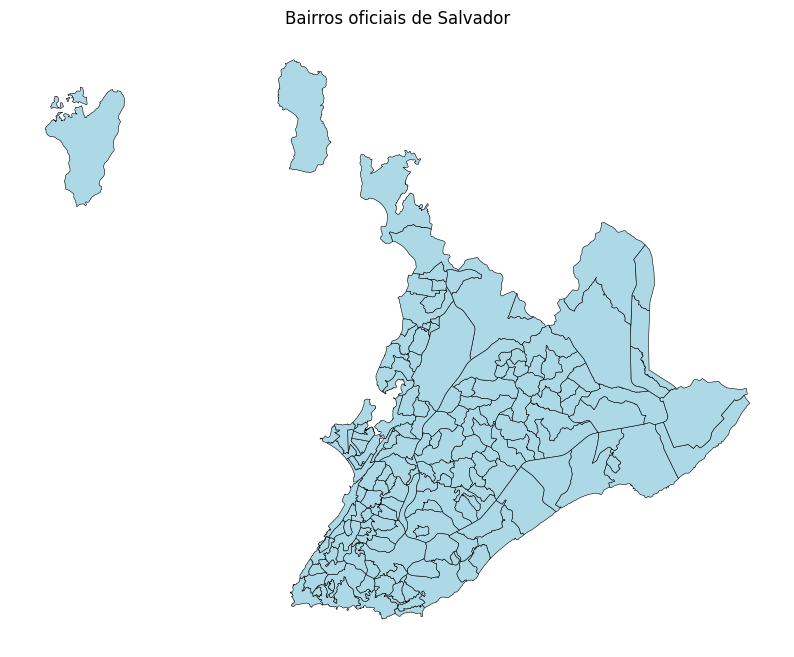

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

bairros.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="black",
    linewidth=0.4
)

ax.set_title("Bairros oficiais de Salvador")
ax.set_axis_off()

plt.show()